In [1]:
import os
import sys

import itertools
import joblib
import numpy as np
import pandas as pd
from sklearn.neighbors import LocalOutlierFactor

sys.path.insert(0, '../../..') # Load Parent directory to import utils
from utils.helper_functions import normalize_series
from utils.metrics import movement_level_confusion
from utils.plotting import plot_movement_data
from utils.helper_functions import load_outlier_data
from utils.constants import Configs
from utils.helper_functions import save_loso_results
from utils.loso_models.lof_detector import LOFDetector
from utils.loso_pipeline import run_loso_evaluation
from utils.bootstrap_utils import compute_bootstrap_ci_all_levels
from utils.helper_functions import append_experiment_record
from utils.helper_functions import calculate_matrix_trash_percentage
from utils.dtw_radius import load_dtw_matrices

ALGORITHM_NAME = 'LOF'
MODEL_REPRESENTATION = 'ShapeBased'

TARGET_MOVEMENT = 'Pick'
EXTRACT_SCORES = True

/home/hugo-guimar-es/Documents/GitHub/wrist-anomaly-detection/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/hugo-guimar-es/Documents/GitHub/wrist-anomaly-detection/.venv/lib/python3.11/site-packages/tslearn/bases/bases.py:16: UserWarning: h5py not installed, hdf5 features will not be supported.
Install h5py to use hdf5 features: http://docs.h5py.org/
  warn(h5py_msg)


In [2]:
# Load the processed data from the csv
cache_path = Configs.SMART_RETAIL_FILTERED_DATA_BIMANUAL
if not os.path.exists(cache_path):
    raise FileNotFoundError(f"Processed data not found at {cache_path}. Please run the data processing notebook first.")

df = pd.read_csv(cache_path)
df = df.sort_values(by=Configs.KEYS + ['step']).reset_index(drop=True)
df_filtered = df[df['movLabel'] == TARGET_MOVEMENT].copy()


In [3]:
# Metadata: one line per movement, same order as the matrices
results_temp_base = df_filtered[Configs.KEYS].drop_duplicates().reset_index(drop=True)
n_movements = len(results_temp_base)

In [4]:
print("\n--- Fusing Outliers into a singular Ground Truth ---")

# Load the known outliers from the csv
outliers_left_csv, _  = load_outlier_data(Configs.SMART_RETAIL_OUTLIERS_LEFT_PATH)
outliers_right_csv, _ = load_outlier_data(Configs.SMART_RETAIL_OUTLIERS_RIGHT_PATH)

def prep_gt(gt, phase):
    """
    Prepare the ground truth data for a specific phase.
    """
    gt = gt[gt['movLabel'] == phase] if 'movLabel' in gt.columns else gt
    return gt.drop_duplicates(subset=Configs.KEYS).reset_index(drop=True)

gt_left  = prep_gt(outliers_left_csv,  TARGET_MOVEMENT)
gt_right = prep_gt(outliers_right_csv, TARGET_MOVEMENT)
gt_union = (pd.concat([gt_left, gt_right])
              .drop_duplicates(subset=Configs.KEYS).reset_index(drop=True))

GT = {'L': gt_left, 'R': gt_right, 'OR': gt_union}
for k, g in GT.items():
    print(f"GT {k}: {len(g)} positivos / {n_movements} movimentos = {len(g)/n_movements*100:.2f}%")

# All positive samples must exist in the metadata
base_keys = set(map(tuple, results_temp_base[Configs.KEYS].values))
for k, g in GT.items():
    missing = [t for t in map(tuple, g[Configs.KEYS].values) if t not in base_keys]
    assert not missing, f"GT {k}: {len(missing)} positivos sem movimento correspondente"


--- Fusing Outliers into a singular Ground Truth ---
Loading outlier data from /home/hugo-guimar-es/Documents/GitHub/wrist-anomaly-detection/Data/SmartRetail/outliers/outliers_left.csv
Loading outlier data from /home/hugo-guimar-es/Documents/GitHub/wrist-anomaly-detection/Data/SmartRetail/outliers/outliers_right.csv
GT L: 2 positivos / 380 movimentos = 0.53%
GT R: 2 positivos / 380 movimentos = 0.53%
GT OR: 3 positivos / 380 movimentos = 0.79%


In [5]:
# # Discard from dataset
# df.drop(df[df['sub']== 13].index, inplace=True)

# # Discard from outliers csv
# outliers_bimanual.drop(outliers_bimanual[outliers_bimanual['sub'] == 13].index, inplace=True)
# outliers_bimanual[outliers_bimanual['sub'] == 13]

In [6]:
group_array = [
    'x_L', 'y_L', 'z_L', # Left Arm
    'x_R', 'y_R', 'z_R' # Right Arm
]
sample_size = None

X_movement = normalize_series(
        df_input=df,
        movLabel_filter=TARGET_MOVEMENT,
        useScaler=False,
        group_array=group_array,
        sample_size=sample_size
)  # shape (n_samples, T, 18)

Processing time series: 100%|██████████| 380/380 [00:00<00:00, 6084.48it/s]

Shape of first series: (106, 6)


Shape of formatted series: (380, 461, 6)


In [ ]:
# =========================================================================
# Base vars for future calculations 
# =========================================================================

n_positives = {k: len(g) for k, g in GT.items()}

def get_base_vars(gt_key: str) -> tuple:
    gt_used = GT[gt_key]

    # Ground truth used for evalution on this run
    total_known_outliers = len(gt_used)

    # Movement-level anomalies
    known_outlier_rate = total_known_outliers / n_movements if n_movements > 0 else 0.0
    known_percentage = known_outlier_rate * 100
    
    # print(f"GT used ({"Union"}): {total_known_outliers} positives / {n_movements} movements = {known_percentage:.2f}%")
    return gt_used, total_known_outliers, known_percentage


# Sincronization: series matrix (X_movement) and DTW matrix must have the same number of rows as the metadata
if X_movement.shape[0] != n_movements:
    raise ValueError(f"X_movement ({X_movement.shape[0]}) != metadata ({n_movements})")
# if dtw_matrix.shape[0] != n_movements:
    # raise ValueError(f"DTW ({dtw_matrix.shape[0]}) != metadata ({n_movements})")


# print(f"✅ Sincronization OK. Lines: X={X_movement.shape[0]} | DTW={dtw_matrix.shape[0]} | metadata={n_movements}")
print(f"Phase: {TARGET_MOVEMENT}")
print(f"positives by ground truth: {n_positives}")

Phase: Pick
positives by ground truth: {'L': 2, 'R': 2, 'OR': 3}


## Local Outlier Factor (LOF)

### Grid Search

In [ ]:
n_neighbors_options = [3, 5, 7, 10, 15, 20]

param_grid = [
    {'n_neighbors': n, 'contamination': c} 
    for n, c in itertools.product(n_neighbors_options, Configs.CONTAMINATION_GRID)
]

matrices = load_dtw_matrices(TARGET_MOVEMENT, Configs.DTW_RADIUS_Seconds, Configs.late_fusion_dtw_matrix_path)

for exp in Configs.EXPERIMENTS:
    print(f"\n\n--- Running experiment: {exp.exp_id} ---")
    
    gt_used, total_known_outliers, known_percentage = get_base_vars(exp.gt_key)

    loso_results = run_loso_evaluation(
        detector_class=LOFDetector, 
        param_grid=param_grid,
        data_matrix=matrices[0.5], # TODO placeholder, replaced per fold TODO
        metadata_df=results_temp_base,
        known_outliers_df=gt_used,
        metric_type='precomputed',
        compute_trial_level=False,
        extract_scores=EXTRACT_SCORES,
        print_results=False,
        dtw_matrices=matrices
    )

    save_loso_results(
        model_name=ALGORITHM_NAME,
        representation=MODEL_REPRESENTATION,
        experiment_name=exp.exp_id,
        target_movement=TARGET_MOVEMENT,
        loso_results=loso_results,
    )

    # Compute bootstrap confidence intervals for the results
    ci_results = compute_bootstrap_ci_all_levels(loso_results, compute_scores=EXTRACT_SCORES, seed=42)

    # Append the results to the summary CSV
    append_experiment_record(
        summary_path=Configs.loso_model_summary_path(MODEL_REPRESENTATION, exp.gt_key),
        phase=TARGET_MOVEMENT,
        representation=MODEL_REPRESENTATION,
        experiment_name=exp.exp_id,
        algorithm=ALGORITHM_NAME,
        total_samples=n_movements,
        loso_results=loso_results,
        bootstrap_results=ci_results,
    )



--- Running experiment: E1 ---
LOSO Cross-Validation with 19 subjects (2 known positive movements)...
Evaluating Subject: 1 | Evaluating Subject: 2 | Evaluating Subject: 3 | Evaluating Subject: 4 | Evaluating Subject: 5 | Evaluating Subject: 6 | Evaluating Subject: 7 | Evaluating Subject: 8 | Evaluating Subject: 9 | Evaluating Subject: 10 | Evaluating Subject: 11 | Evaluating Subject: 12 | Evaluating Subject: 13 | Evaluating Subject: 14 | Evaluating Subject: 15 | Evaluating Subject: 16 | Evaluating Subject: 17 | Evaluating Subject: 18 | Evaluating Subject: 19 | 
✅ Experiment Summary for LOF - ShapeBased - Pick - E1- 380 Movements (MOVEMENT-level):
Unique Outliers Detected: 134
Rejection Rate: 35.26%
Known Positives in Ground Truth: 2
------------------------------
Total True Positives (Global):  1
Total False Positives (Global): 133
Total False Negatives (Global): 1
Total True Negatives (Global):  245
------------------------------
Blind Precision: 0.75 [0.00–2.31]
Blind Recall:    5

### Train Model

In [ ]:
# best_params = loso_results['Best_Params']
# best_n_neighbors = int(best_params['n_neighbors'])
# best_contamination = best_params['contamination']

# selected_radius = loso_results['Most_Frequent_DTW_Radius']
# selected_dtw_matrix = matrices[selected_radius]      # `matrices` is the dict loaded earlier

In [ ]:
# model = LocalOutlierFactor(n_neighbors=best_n_neighbors, contamination=best_contamination, n_jobs=-1, metric='precomputed')
# labels = model.fit_predict(selected_dtw_matrix)
# joblib.dump(model, Configs.final_model_file(ALGORITHM_NAME, MODEL_REPRESENTATION, TARGET_MOVEMENT))

# outlier_indices = np.where(labels == -1)[0]
# n_outliers = len(outlier_indices)

In [ ]:
# # Reconstruct metadata for cross-referencing with the original CSV
# grouped_keys = df_filtered.groupby(['sub', 'repID', 'movID', 'movLabel'], sort=False).groups.keys()
# metadata_df = pd.DataFrame(list(grouped_keys), columns=['sub', 'repID', 'movID', 'movLabel'])

# n_unique_outliers, correct_trash_pct = calculate_matrix_trash_percentage(outlier_indices, metadata_df)

# X_movement_clean = np.delete(X_movement, outlier_indices, axis=0)
# X_movement_outliers = X_movement[outlier_indices]

# print(f"Raw Outlier Trials Detected: {n_outliers}")
# print(f"Unique Outlier Trials Detected: {n_unique_outliers}")
# print(f"Detected Trash Percentage (sub + repID + movID): {(n_outliers/len(selected_dtw_matrix)*100):.2f}%") # instead of total_trials, I can use len(dtw_matrix)
# print(f"Detected Trash Percentage (sub + repID): {correct_trash_pct:.2f}%")

Raw Outlier Trials Detected: 69
Unique Outlier Trials Detected: 45
Detected Trash Percentage (sub + repID + movID): 18.16%
Detected Trash Percentage (sub + repID): 47.37%


In [ ]:
# real_outliers_info = metadata_df.iloc[outlier_indices][["sub", "repID", "movID", "movLabel"]]
# identified_unique = real_outliers_info.drop_duplicates(subset=['sub', 'repID'])

# print("Outlier Details:")
# print(real_outliers_info)

Outlier Details:
     sub  repID  movID movLabel
0      1      1      1     Pick
5      1      2      3     Pick
20     2      1      1     Pick
40     3      1      1     Pick
48     3      3      1     Pick
..   ...    ...    ...      ...
317   16      5      3     Pick
340   18      1      1     Pick
346   18      2      5     Pick
355   18      4      7     Pick
378   19      5      5     Pick

[69 rows x 4 columns]


In [ ]:
# identified_unique = real_outliers_info.drop_duplicates(subset=['sub', 'repID'])

# matched_outliers = pd.merge(identified_unique, gt_used, on=['sub', 'repID'], how='inner')

# missing_outliers = pd.merge(gt_used, identified_unique, on=['sub', 'repID'], how='left', indicator=True)
# missing_outliers = missing_outliers[missing_outliers['_merge'] == 'left_only']

# metrics = movement_level_confusion(metadata_df, outlier_indices, gt_used, Configs.KEYS)

TP=3 FP=66 FN=0 TN=311 | P=4.35% R=100.00% F2=18.52% MCC=0.19


### Plot Things

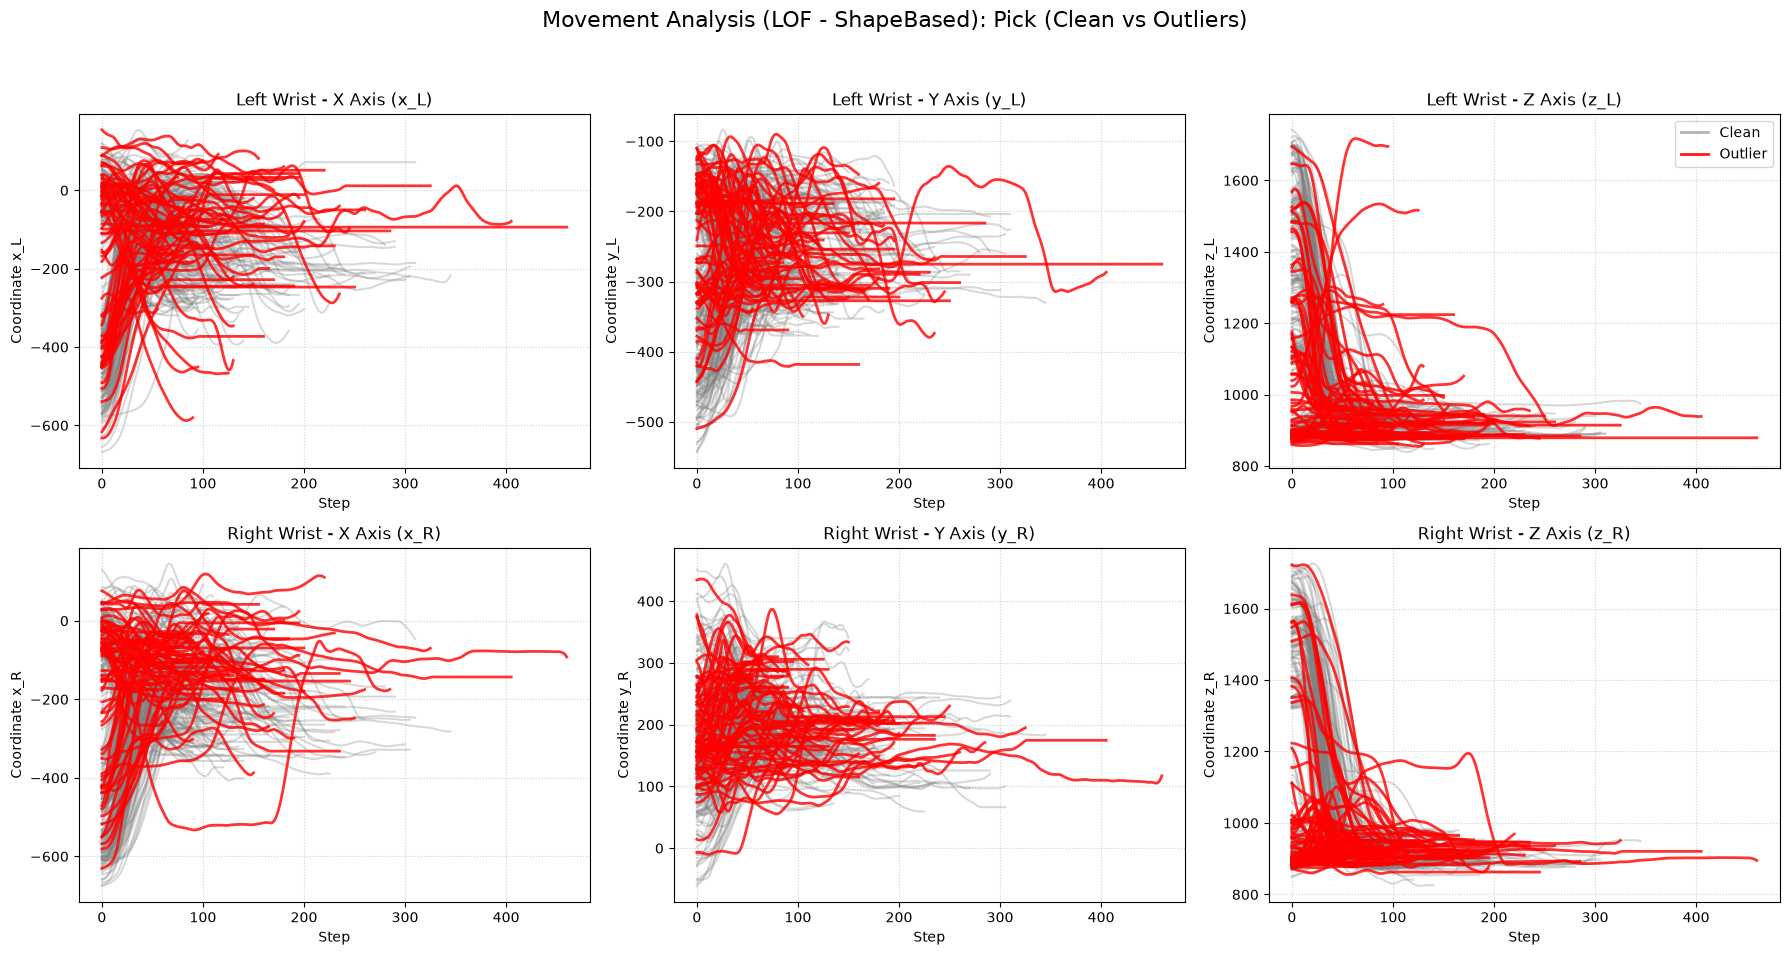

In [ ]:
# plot_movement_data(
#     clean_data=X_movement_clean,
#     outlier_data=X_movement_outliers,
#     target_movement=TARGET_MOVEMENT,
#     algorithm_name=ALGORITHM_NAME,
#     save_fig=Configs.SAVE_PLOTS,
#     save_path=Configs.DESKTOP_PATH,
#     model_representation=MODEL_REPRESENTATION
# )

### Exemplo de exportação

In [ ]:
# Exemplo 1 - Claude

# oof = loso_results['OOF_Movement'][KEYS + ['pred_is_outlier', 'anomaly_score']].copy()
# oof['pred_final'] = 0
# oof.loc[oof.set_index(KEYS).index.isin(
#     metadata_df.iloc[outlier_indices].set_index(KEYS).index), 'pred_final'] = 1
# oof['algorithm'], oof['experiment'], oof['phase'] = ALGORITHM_NAME, exp['name'], TARGET_MOVEMENT
# oof.to_csv(f"exports/flags_{ALGORITHM_NAME}_{exp['name']}_{TARGET_MOVEMENT}.csv", index=False)

In [ ]:
# Exemplo 2 - Testado no ICater

# # ---------------------------------------------------------
# # PASSAR A FACA: Limpar e isolar APENAS o movimento pretendido (DTW)
# # ---------------------------------------------------------

# # 0. Filtrar o DataFrame bruto para ter APENAS o movimento alvo
# df_target_only = df[df['movLabel'] == TARGET_MOVEMENT].copy()

# # 1. Garantir que temos apenas as chaves identificadoras dos outliers
# # CORREÇÃO: Remover o 'movLabel'. O trio de IDs é a impressão digital perfeita!
# # O drop_duplicates() extra garante que não há duplicações na lista de corte
# outliers_keys = real_outliers_info[['sub', 'repID', 'movID']].drop_duplicates().copy()

# # 2. Fazer um merge (Anti-Join) do dataframe FILTRADO com a lista de outliers
# # O indicator=True cria uma coluna chamada '_merge' que nos diz de onde veio a linha
# df_cleaned = pd.merge(df_target_only, outliers_keys, on=['sub', 'repID', 'movID'], how='left', indicator=True)

# # 3. Manter APENAS as linhas que estão limpas ('left_only')
# df_cleaned = df_cleaned[df_cleaned['_merge'] == 'left_only'].drop(columns=['_merge'])

# # --- VERIFICAÇÃO ---
# print(f"--- RESUMO DA LIMPEZA ({TARGET_MOVEMENT}) ---")
# print(f"Linhas do movimento {TARGET_MOVEMENT} antes da limpeza: {len(df_target_only)}")
# print(f"Linhas removidas (pertencentes a outliers): {len(df_target_only) - len(df_cleaned)}")
# print(f"Linhas do movimento {TARGET_MOVEMENT} limpas: {len(df_cleaned)}")

# # Para confirmar os movimentos únicos que sobraram do TARGET_MOVEMENT
# movimentos_restantes = df_cleaned[['sub', 'repID', 'movID']].drop_duplicates()
# n_removidos_esperados = len(outliers_keys)

# print(f"\nMovimentos '{TARGET_MOVEMENT}' que SOBRARAM: {len(movimentos_restantes)}")
# print(f"Movimentos originais eram {total_trials}, removemos {n_removidos_esperados}, batem certo? {len(movimentos_restantes) == (total_trials - n_removidos_esperados)}")

# # 4. Guardar o novo dataset limpo APENAS para este movimento
# # Usa uma f-string para o nome do ficheiro refletir automaticamente o TARGET_MOVEMENT
# save_dir = str(Configs.inliers_late_fusion_dtw_path(TARGET_MOVEMENT))

# df_cleaned.to_csv(save_dir, index=False)
# print(f"\n✅ Inliers do {TARGET_MOVEMENT} guardados com sucesso em: {save_dir}")